# Step 10 · Build and inspect host-specific Explorer embeddings

After notebook 09 validates the run, this step builds the additive Explorer database for the configured host and pathogen selection. The builder recomputes IMSTE and UMAP independently for every eligible host × pathogen-group cohort, preserves unrelated host and pathogen records, and records fit provenance. If one method is unstable, a successful alternative remains available. This notebook inspects an available map for the configured cohort using the saved run configuration.


In [1]:
import gzip, json, math, sys
from pathlib import Path
from IPython.display import display
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'pathogen_atlas_v4').is_dir():
    raise RuntimeError('Open this notebook from the V4 repository')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
from _shared import configure_notebook, configured_run_id, staging_root_for_config
sys.path.insert(0, str(PROJECT_ROOT / 'sites/pathogen-atlas-explorer/scripts'))
from build_v4_site_data import build_site_data
ROOT = PROJECT_ROOT
RUN_ID = configured_run_id(ROOT)
ROOT, LOG, LOG_PATH = configure_notebook('10_inspect_embeddings', RUN_ID)
RUN_DIR = ROOT / 'data/v4/runs' / RUN_ID
RUN_RECORD = json.loads((RUN_DIR / 'resolved_config.json').read_text(encoding='utf-8'))
CONFIG = RUN_RECORD['source_config']
STAGING_ROOT = staging_root_for_config(ROOT, CONFIG)
SITE_ROOT = ROOT / 'sites/pathogen-atlas-explorer'
BUILD_REPORT = build_site_data(RUN_DIR, STAGING_ROOT, SITE_ROOT, dist_root=SITE_ROOT / 'dist')
print('Explorer database rebuilt:', BUILD_REPORT)
LOG.info('Explorer database built for run=%s profiles=%d evidence=%d', RUN_ID, BUILD_REPORT['species_profiles'], BUILD_REPORT['evidence_records'])

PAYLOAD_PATH = SITE_ROOT / 'explorer-data.json.gz'
payload = json.loads(gzip.open(PAYLOAD_PATH, 'rt', encoding='utf-8').read())
run_pathogens = __import__('pandas').read_parquet(RUN_DIR / 'taxonomy/pathogens.parquet')
selected_ids = set(map(str, RUN_RECORD['pathogen_ids']))
selected_pathogens = run_pathogens.loc[run_pathogens.pathogen_id.astype(str).isin(selected_ids)]
selected_groups = sorted(selected_pathogens.pathogen_group.astype(str).unique())
selected_hosts = list(map(str, RUN_RECORD['host_ids']))
if not selected_groups or not selected_hosts:
    raise RuntimeError('The resolved run has no host × pathogen-group cohort to inspect.')
# Use a configured cohort for the notebook's plot. The builder above fits all eligible selected cohorts.
HOST_ID_TO_PLOT = selected_hosts[0]
GROUP_TO_PLOT = selected_groups[0]
TAXA_PATH = SITE_ROOT / 'taxa' / f'{GROUP_TO_PLOT}.json.gz'
taxa = json.loads(gzip.open(TAXA_PATH, 'rt', encoding='utf-8').read())
profiles = []
for record in taxa:
    row = dict(zip(payload['species_columns'], record))
    pair = (row.get('pair_profiles') or {}).get(HOST_ID_TO_PLOT) or {}
    profiles.append({**pair, 'pathogen_id': row['organism_id'], 'accepted_name': row['accepted_name']})
print(f'Run: {RUN_ID} | hosts: {selected_hosts} | pathogen groups: {selected_groups}')
print(f'Inspecting: {HOST_ID_TO_PLOT} × {GROUP_TO_PLOT} | taxonomy rows: {len(profiles)}')


2026-11-03 10:56 INFO Notebook session started at 2026-11-03T10:56:27.998415+00:00


2026-11-03 10:56 INFO Project root: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4


2026-11-03 10:56 INFO Run log: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/logs/pilot-v1/10_inspect_embeddings.log


2026-11-03 10:56 INFO Explorer database built for run=pilot-v1 profiles=202903 evidence=35611


Explorer database rebuilt: {'run_id': 'pilot-v1', 'screening_question_version': 'pathogen-screen-system1-v2-threshold-0.7', 'screening_yes_probability_threshold': 0.7, 'pathogen_species': 202900, 'hosts': ['ncbi:3847', 'ncbi:4530', 'ncbi:4565', 'ncbi:4577', 'ncbi:9031', 'ncbi:9606', 'ncbi:9823', 'ncbi:9913', 'ncbi:9940', 'ncbi:8030', 'ncbi:8049'], 'possible_host_pathogen_pairs': 2231900, 'pair_profiles_available': 23502, 'supported_pairs': 2419, 'current_run_candidate_pairs': 3548, 'current_run_pubmed_hit_pairs': 81, 'current_run_sampled_records': 379, 'human_supported_profiles': 2400, 'human_supporting_pmids': 35446, 'shared_virus_coordinates_in_rice_view': 257, 'supported_pmids': 35543, 'feature_screen_decisions': 7863, 'species_profiles': 202903, 'evidence_records': 35611, 'payload': '/Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/sites/pathogen-atlas-explorer/explorer-data.json.gz'}
Run: pilot-v1 | hosts:

## Step 1 · Read the saved coordinates

The build step fits both maps to accepted/supported profiles with complete, variable feature data. Each method is saved only when it produces finite, non-collapsed coordinates; failure in one method does not discard the other. Cohorts below the minimum of three profiles remain available in the catalog and are reported as ineligible for a 2D fit.


In [2]:
EMBEDDING_KEY = f'{HOST_ID_TO_PLOT}::{GROUP_TO_PLOT}'
available_methods = [method for method in ('IMSTE', 'UMAP')
                    if payload.get('embedding_runs', {}).get(f'{EMBEDDING_KEY}::{method}')]
EMBEDDING_METHOD = available_methods[0] if available_methods else 'IMSTE'
plot_data = []
for profile in profiles:
    if str(profile.get('pair_selection_status', '')).casefold() not in {'accepted', 'supported'}:
        continue
    coordinates = (profile.get('embedding_coordinates') or {}).get(EMBEDDING_METHOD)
    if coordinates is None and EMBEDDING_METHOD == 'IMSTE':
        coordinates = profile
    if coordinates is None:
        continue
    try:
        x, y = float(coordinates.get('x')), float(coordinates.get('y'))
    except (TypeError, ValueError):
        continue
    if math.isfinite(x) and math.isfinite(y):
        plot_data.append({'pathogen_id': profile['pathogen_id'], 'accepted_name': profile['accepted_name'], 'x': x, 'y': y})
EMBEDDING_RUN = (payload.get('embedding_runs', {}).get(f'{EMBEDDING_KEY}::{EMBEDDING_METHOD}')
                 or payload.get('embedding_runs', {}).get(EMBEDDING_KEY)
                 or payload.get('embedding_runs', {}).get(HOST_ID_TO_PLOT))
print(f'Saved finite coordinates: {len(plot_data)} | embedding: {EMBEDDING_METHOD} | key: {EMBEDDING_KEY}')
print('Embedding metadata:', json.dumps(EMBEDDING_RUN, indent=2))
LOG.info('Saved %s coordinates host=%s group=%s profiles=%d', EMBEDDING_METHOD, HOST_ID_TO_PLOT, GROUP_TO_PLOT, len(plot_data))


2026-11-03 10:56 INFO Saved IMSTE coordinates host=ncbi:9606 group=oomycetes profiles=5


Saved finite coordinates: 5 | embedding key: ncbi:9606::oomycetes
Embedding metadata: {
  "embedding": "IMSTE",
  "estimator": "IteratedMinimumSpanningTreeEmbedder",
  "imste_version": "0.1.0",
  "host_id": "ncbi:9606",
  "pathogen_group": "oomycetes",
  "n_species": 5,
  "n_features": 36,
  "feature_ids": [
    "abstract_reports_disease",
    "animal_asymptomatic_carriage",
    "animal_morbidity",
    "animal_mortality",
    "animal_neurologic_disease",
    "cardiovascular",
    "cutaneous",
    "digestive",
    "domesticated_animals",
    "epidemiology",
    "geography",
    "immunocompromised",
    "immunosuppressed",
    "mammals",
    "oomycete_sporangia",
    "oomycete_zoospores",
    "operation",
    "pair_device_association",
    "pair_diagnostic_specimen",
    "pair_environmental_reservoir",
    "pair_host_entry_route",
    "pair_immune_evasion",
    "pair_tissue_tropism",
    "patient_age",
    "patient_occupation",
    "pets",
    "plants",
    "priority_species",
    "recre

## Step 2 · Render the saved coordinates

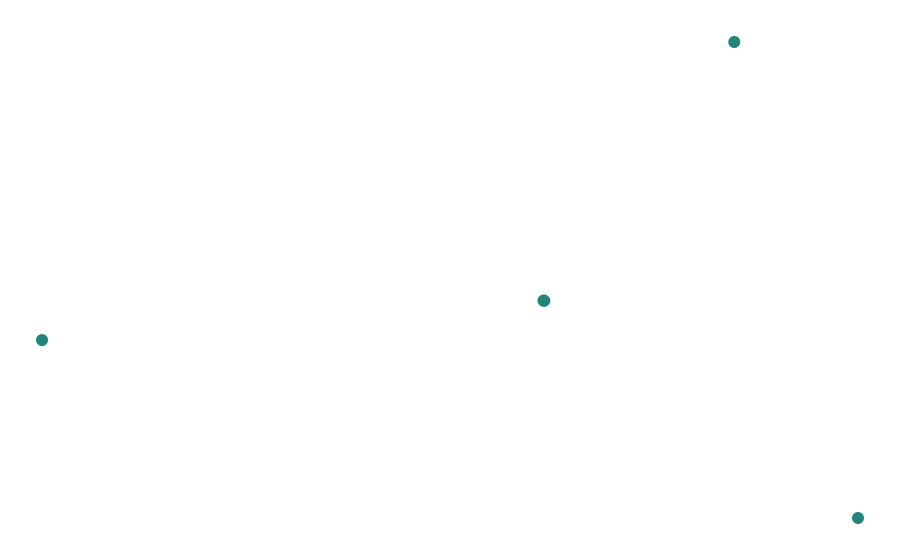

SVG saved: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/Pathogen Atlas/Pathogen Atlas/Pathogen Atlas Data Acquisition/version4/data/v4/plots/oomycetes-ncbi-9606-imste.svg


In [3]:
from html import escape
from IPython.display import SVG, display
if len(plot_data) >= 3:
    width, height, pad = 900, 560, 42
    xs, ys = [p['x'] for p in plot_data], [p['y'] for p in plot_data]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    if x0 == x1: x1 = x0 + 1
    if y0 == y1: y1 = y0 + 1
    marks = []
    for point in plot_data:
        x = pad + (point['x'] - x0) / (x1 - x0) * (width - 2 * pad)
        y = height - pad - (point['y'] - y0) / (y1 - y0) * (height - 2 * pad)
        marks.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="6" fill="#21857b"><title>{escape(point["accepted_name"])}</title></circle>')
    svg = (f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">'
           f'<rect width="100%" height="100%" fill="white"/>{"".join(marks)}</svg>')
    display(SVG(svg))
    PLOT_DIR = ROOT / 'data/v4/plots'
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    SVG_PATH = PLOT_DIR / f'{GROUP_TO_PLOT}-{HOST_ID_TO_PLOT.replace(":", "-")}-{EMBEDDING_METHOD.casefold()}.svg'
    SVG_PATH.write_text(svg, encoding='utf-8')
    print('SVG saved:', SVG_PATH)
else:
    svg = None
    print('SVG skipped: fewer than three profiles have saved 2D coordinates.')


## Step 3 · Verify the Explorer handoff

The profile shard and top-level payload are both rebuilt in this step. Existing pair keys remain additive; complete profiles carry both IMSTE and UMAP coordinates and each map has a separate host/group/method fit record.

In [4]:
if len(plot_data) >= 3:
    assert all(math.isfinite(point['x']) and math.isfinite(point['y']) for point in plot_data)
    if EMBEDDING_RUN and EMBEDDING_RUN.get('embedding') != EMBEDDING_METHOD:
        raise RuntimeError(f'Unexpected embedding method for {EMBEDDING_KEY}: {EMBEDDING_RUN.get("embedding")}')
    print(f'Explorer {EMBEDDING_METHOD} map ready: {HOST_ID_TO_PLOT} × {GROUP_TO_PLOT}, {len(plot_data)} profiles')
else:
    print(f'No 2D map for {HOST_ID_TO_PLOT} × {GROUP_TO_PLOT}: only {len(plot_data)} profiles have saved coordinates; Explorer catalog data remains available.')
LOG.info('Explorer handoff verified method=%s host=%s group=%s plotted=%d', EMBEDDING_METHOD, HOST_ID_TO_PLOT, GROUP_TO_PLOT, len(plot_data))


2026-11-03 10:56 INFO Explorer handoff verified host=ncbi:9606 group=oomycetes plotted=5


Explorer 2D map ready: ncbi:9606 × oomycetes, 5 profiles
